# ДЗ
# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.
# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.
# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage


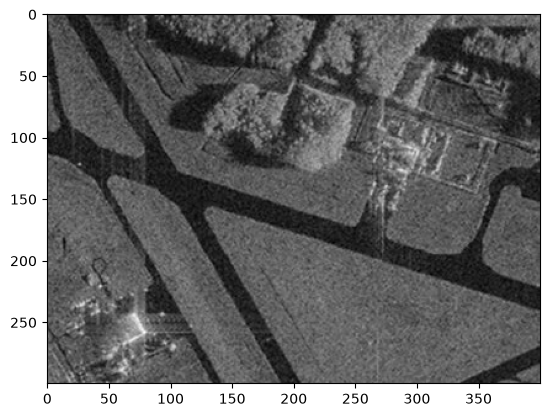

In [2]:
image_lawn = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image_lawn, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap='gray')

In [3]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
                                                            
    if abs(av_val - img[point]) <= T:
        return True
    
    return False
    

In [4]:
def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    kernel = np.ones((2*r + 1, 2*r + 1), np.uint8)
    while count > 0:
        neighbors = cv2.dilate(mask, kernel)
        candidates = np.argwhere((neighbors > 0) & (mask == 0))
        local_mask = np.zeros(image.shape, np.uint8)
        for i, j in candidates:
            if homo_fun(image, mask, (i, j), T):
                local_mask[i, j] = 1
        count = np.count_nonzero(local_mask)
        mask += local_mask

    return mask*255

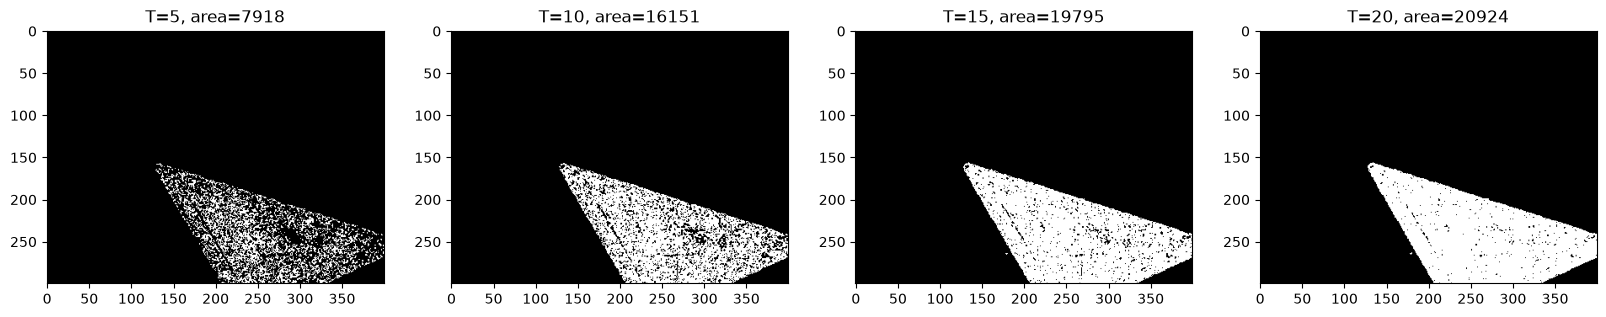

In [5]:
seed_point = (250, 250)
t_params = [5, 10, 15, 20]
r_param = 4
t_param = t_params[3]

fig, axs = plt.subplots(1, len(t_params), figsize=(20, 5))

for ax, T in zip(axs, t_params):
    mask_T = region_growing(image_gray, seed_point, homo_average, r_param, T)
    ax.imshow(mask_T, cmap='gray')
    ax.set_title(f'T={T}, area={np.count_nonzero(mask_T)}')
plt.show()

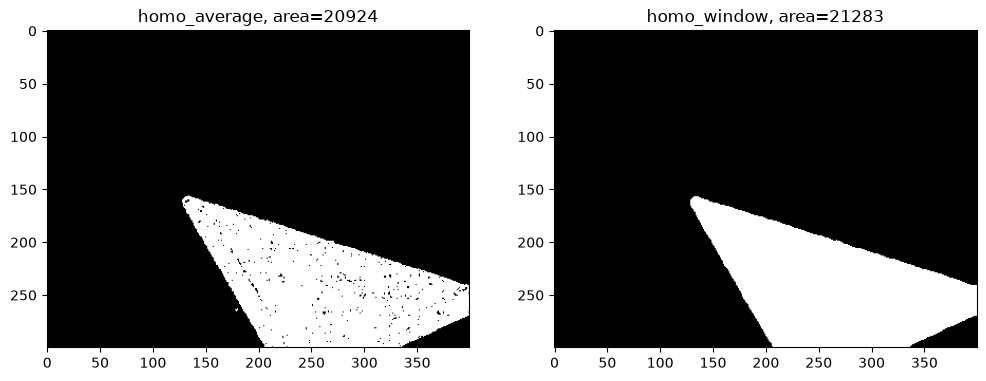

In [ ]:

#custom homo using window of 5x5
def homo_window(img, mask, point, T):
    i, j = point
    win = img[max(i - 2, 0):i + 3, max(j - 2, 0):j + 3]
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])

    if abs(av_val - win.mean()) <= T:
        return True

    return False


mask_avg = region_growing(image_gray, seed_point, homo_average, r_param, t_param)
mask_win = region_growing(image_gray, seed_point, homo_window, r_param, t_param)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].imshow(mask_avg, cmap='gray')
axs[0].set_title(f'homo_average, area={np.count_nonzero(mask_avg)}')
axs[1].imshow(mask_win, cmap='gray')
axs[1].set_title(f'homo_window, area={np.count_nonzero(mask_win)}')
plt.show()

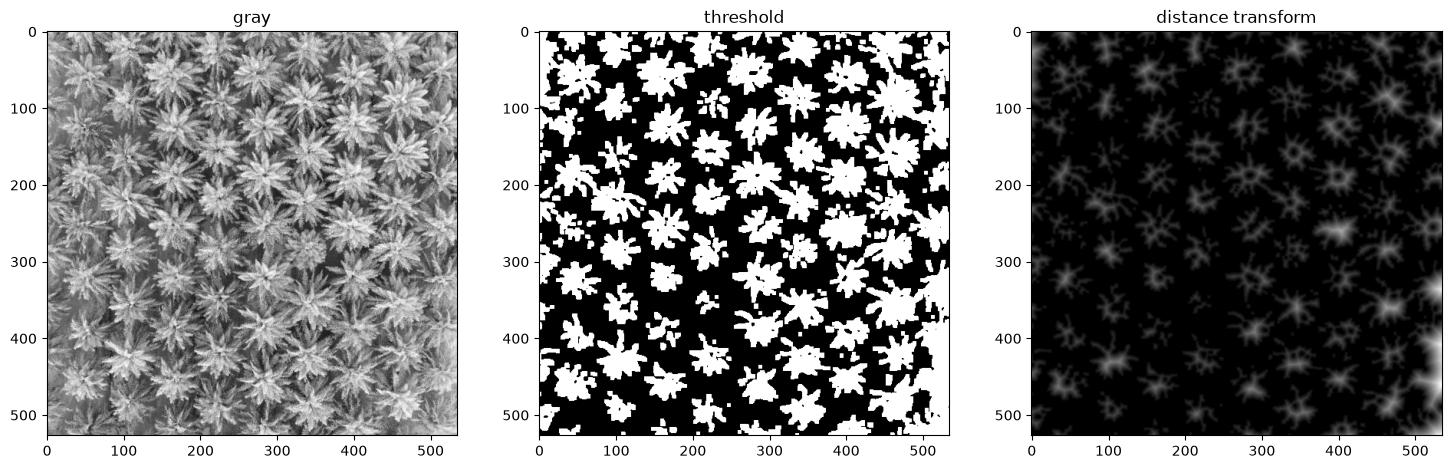

In [7]:
image_palm = cv2.imread('palm_1.JPG')
image_palm_gray = cv2.cvtColor(image_palm, cv2.COLOR_BGR2GRAY)

blur_palm = cv2.GaussianBlur(image_palm_gray, (5, 5), 0)
ret, thresh_palm = cv2.threshold(blur_palm, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
kernel = np.ones((3, 3), np.uint8)
thresh_palm = cv2.morphologyEx(thresh_palm, cv2.MORPH_OPEN, kernel, iterations=2)

dist_palm = cv2.distanceTransform(thresh_palm, cv2.DIST_L2, 5)

fig, axs = plt.subplots(1, 3, figsize=(18, 6))
axs[0].imshow(image_palm_gray, cmap='gray')
axs[0].set_title('gray')
axs[1].imshow(thresh_palm, cmap='gray')
axs[1].set_title('threshold')
axs[2].imshow(dist_palm, cmap='gray')
axs[2].set_title('distance transform')
plt.show()

In [8]:
def count_palms(min_radius):
    ret, sure_fg = cv2.threshold(dist_palm, min_radius, 255, cv2.THRESH_BINARY)
    sure_fg = sure_fg.astype(np.uint8)
    sure_bg = cv2.dilate(thresh_palm, kernel, iterations=3)
    unknown = cv2.subtract(sure_bg, sure_fg)
    ret, markers = cv2.connectedComponents(sure_fg)
    markers = markers + 1
    markers[unknown == 255] = 0
    markers = cv2.watershed(image_palm, markers)
    labels = np.unique(markers)
    count = len(labels) - 1 - (1 if -1 in labels else 0)
    return markers, count

In [9]:
for min_radius in [5, 6, 7, 8]:
    markers_palm, n_palms = count_palms(min_radius)
    print(f'min_radius={min_radius}: palms={n_palms}')

min_radius=5: palms=182
min_radius=6: palms=147
min_radius=7: palms=140
min_radius=8: palms=97


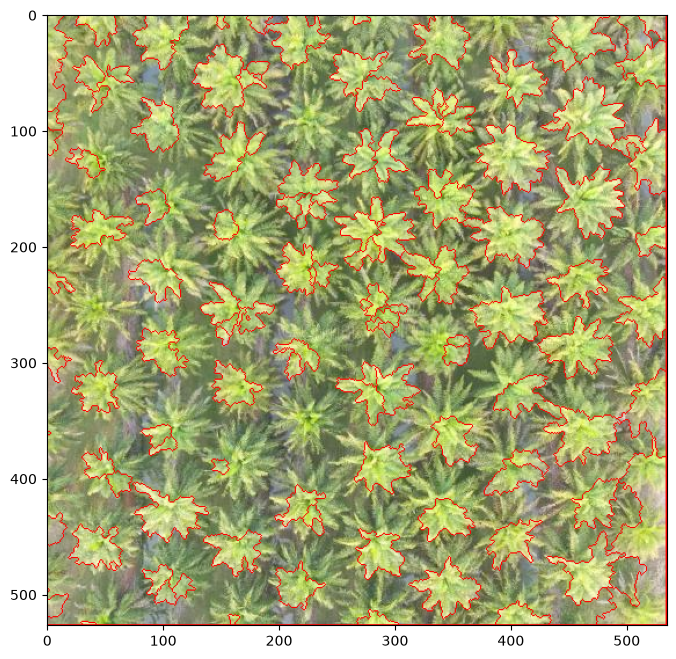

Number of palm trees: 140


In [11]:
markers_palm, n_palms = count_palms(7)
image_result = image_palm.copy()
image_result[markers_palm == -1] = (0, 0, 255)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(image_result, cv2.COLOR_BGR2RGB))
plt.show()
print(f'Number of palm trees: {n_palms}')
